# **Error estimation of Cartesian Model**
*All the conditions are fully observable and clean (no noise)*.


*We compare the NF decoding error, the diffusion generation error, and joint distribution approximation error.*

In [1]:
%env CUDA_VISIBLE_DEVICES = 0
import torch
import numpy as np
import matplotlib.pyplot as plt

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    dev = "cuda"
else:
    dev = "cpu"

device = torch.device(dev)
print(device)

env: CUDA_VISIBLE_DEVICES=0


cuda


### Load Unconditional Model

In [2]:
u_net_model = create_model(image_size= 64,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4,2,1",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_unet_experiment1/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

loaded unet


## **Fully observed conditions**

### Conditional Operator and Noise

In [32]:
operator =  get_operator(name='cartesian_superresolution',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1999,
                        ds_size=999999,
                        vanilla_flag=True,
                        noise=[13e5, 0.1, 2.1]
                        )

/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:666: UserWarning: Vanilla flag is set to True, using the original data without downsampling!
  warnings.warn(f"Vanilla flag is set to True, using the original data without downsampling!")
/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:668: UserWarning: Noise is set to [1300000.0, 0.1, 2.1], will add noise to the output data.
  warnings.warn(f"Noise is set to {noise}, will add noise to the output data.")


Simulation data loaded, with shape (64, 64, 64, 3)


### Conditioning Method

In [ ]:
noiser = get_noise(sigma=0.0, name='gaussian')
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

### Sampler

In [47]:
sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

### Generate Samples

In [48]:
no_of_samples = 2
time_length = 64
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Adding noise with levels [1300000.0, 0.1, 2.1] to the data.


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

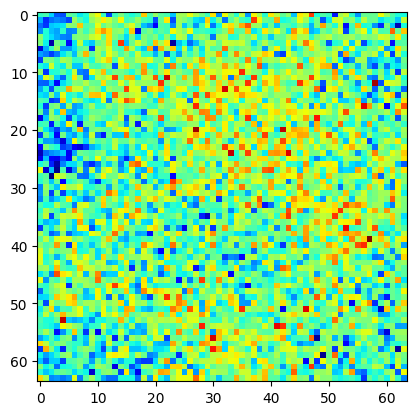

In [49]:
plt.imshow(measurement_ref[0, 0, ...].detach().cpu().numpy(), cmap='jet')

In [1]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")

NameError: name 'torch' is not defined

### Decoding latents to flow fields

In [50]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film

nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)

print('nf loaded')

nf loaded


In [51]:
# gen_latents = torch.load('conditional_outputs/pts/generated_latents_Cart8xSR.pt')
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'error_estimation_outputs/CNF_out_full_K_0.10.pt')

CNF output shape: torch.Size([2, 64, 64, 64, 3])


### ***SIREN OUT***

In [12]:
sys.path.append('../../../ConditionalNeuralField')
from ConditionalNeuralField.scripts.train import LatentContainer
checkpoint_latent = ckpt["hidden_states"]
N_samples = checkpoint_latent["latents"].shape[0]
latents = LatentContainer(N_samples, 256, 2)
latents.load_state_dict(checkpoint_latent)

print(f"latenet shape: {latents.latents.shape}")

latenet shape: torch.Size([128000, 256])


In [13]:
test_sample_id = 1999
batch_size = 64
input_latent = latents(torch.arange(test_sample_id*64, test_sample_id*64+64))
input_latent = input_latent.to(device)    # <64,1,1,128> latents

In [14]:
with torch.no_grad():
    siren_out = nf(whole_coords_in, input_latent)


siren_out = operator._unnorm_cnf(siren_out)
siren_out = siren_out.reshape(1, 64, 64, 64, 3)
print(f"siren output shape: {siren_out.shape}")

siren output shape: torch.Size([1, 64, 64, 64, 3])


In [15]:
torch.save(siren_out, 'error_estimation_outputs/siren_out.pt')

## **Load PT**

In [52]:
full_k = torch.load('error_estimation_outputs/CNF_out_full_K.pt', map_location='cpu').detach().numpy()
full_ps = torch.load('error_estimation_outputs/CNF_out_full_PS.pt', map_location='cpu').detach().numpy()
full_all = torch.load('error_estimation_outputs/CNF_out_full_all.pt', map_location='cpu').detach().numpy()
full_k_noise_05 = torch.load('error_estimation_outputs/CNF_out_full_K_0.05.pt', map_location='cpu').detach().numpy()
full_ps_noise_05 = torch.load('error_estimation_outputs/CNF_out_full_PS_0.05.pt', map_location='cpu').detach().numpy()
full_k_noise_10 = torch.load('error_estimation_outputs/CNF_out_full_K_0.10.pt', map_location='cpu').detach().numpy()
full_ps_noise_10 = torch.load('error_estimation_outputs/CNF_out_full_PS_0.10.pt', map_location='cpu').detach().numpy()

siren_out = torch.load('error_estimation_outputs/siren_out.pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {full_k.shape}, SIREN output shape: {siren_out.shape}")

def RMSE(x, x_hat):
    return np.sqrt((x - x_hat) ** 2).mean()

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3), SIREN output shape: (1, 64, 64, 64, 3)


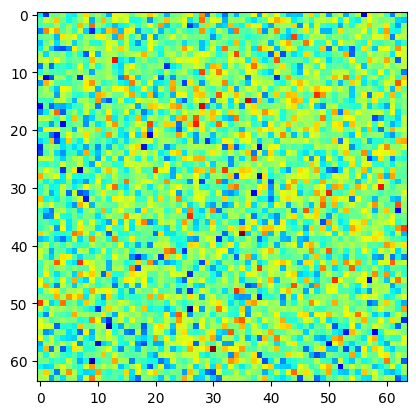

In [41]:
plt.imshow(ref[0, :, :, -1] + np.random.randn(64, 64) * 7, cmap='jet')


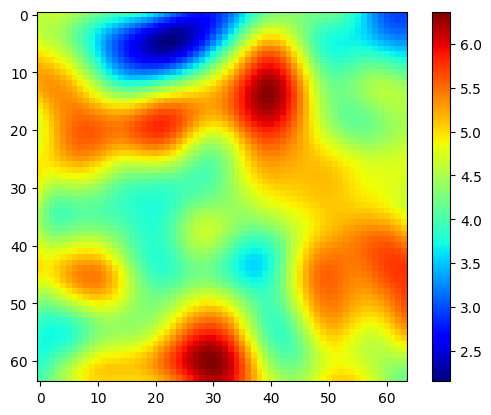

In [54]:
plt.imshow(full_k_noise_10[0, 0, :, :, -1], cmap='jet')
plt.colorbar()

In [7]:
print(ref[0, :, :, -1].mean(), ref[0, :, :, -1].max(), ref[0, :, :, -1].min())
print(ref[:, :, :, 0].mean(), ref[:, :, :, 0].max(), ref[:, :, :, 0].min())
print(ref[:, :, :, 1].mean(), ref[:, :, :, 1].max(), ref[:, :, :, 1].min())

4.805166 6.999442 1.4390993
13191106.0 18207482.0 12000000.0
0.14671016 0.6195004 0.0


In [4]:
siren_k_rmse = RMSE(ref[0, ..., -1], np.mean(siren_out[0, :, ..., -1], axis=0))
print(f"SIREN RMSE: {siren_k_rmse}")
full_k_k_rmse = []
full_ps_k_rmse = []
fulkl_all_k_rmse = []
for i in range(10):
    full_k_k_rmse.append(RMSE(ref[0, ..., -1], np.mean(full_k[i, :, ..., -1], axis=0)))
    full_ps_k_rmse.append(RMSE(ref[0, ..., -1], np.mean(full_ps[i, :, ..., -1], axis=0)))
    fulkl_all_k_rmse.append(RMSE(ref[0, ..., -1], np.mean(full_all[i, :, ..., -1], axis=0)))
print(f"Full K RMSE: {np.mean(full_k_k_rmse)}")
print(f"Full PS RMSE: {np.mean(full_ps_k_rmse)}")
print(f"Full All RMSE: {np.mean(fulkl_all_k_rmse)}")
print(f"Full K RMSE std: {np.std(full_k_k_rmse)}")
print(f"Full PS RMSE std: {np.std(full_ps_k_rmse)}")
print(f"Full All RMSE std: {np.std(fulkl_all_k_rmse)}")

SIREN RMSE: 0.014843501150608063
Full K RMSE: 0.0250067301094532
Full PS RMSE: 0.2968875467777252
Full All RMSE: 0.03249408304691315
Full K RMSE std: 0.0012548607774078846
Full PS RMSE std: 0.01692710816860199
Full All RMSE std: 0.0014156028628349304


In [5]:
means = [siren_k_rmse, np.mean(full_k_k_rmse), np.mean(full_ps_k_rmse), np.mean(fulkl_all_k_rmse)]
stds = [np.nan, np.std(full_k_k_rmse), np.std(full_ps_k_rmse), np.std(fulkl_all_k_rmse)]

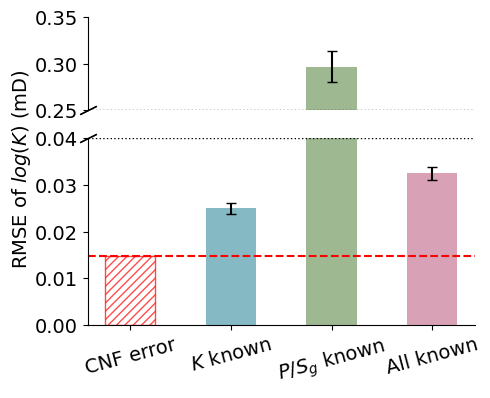

In [25]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(5, 4), gridspec_kw={'height_ratios': [1, 2]})
fig.subplots_adjust(hspace=0.2)

color = ['red', '#529cab', '#759c62', '#c87a97']

# Bar plot on both axes
x = [1, 2, 3, 4]
bars = ax1.bar(x, means, yerr=stds, color=color, capsize=3.5, width=0.5, alpha=0.7)
bars2 = ax2.bar(x, means, yerr=stds, color=color, capsize=3.5, width=0.5, alpha=0.7)

bars2[0].set_facecolor('none')
bars2[0].set_edgecolor('red')
bars2[0].set_hatch('////')

# Broken axis limits
ax1.set_ylim(0.25, 0.35)
ax2.set_ylim(0, 0.04)

# Hide the spines between ax and ax2
ax1.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax2.spines['bottom'].set_visible(True)
ax1.spines['right'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax1.tick_params(bottom=False, labelbottom=False)

ax1.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='y', labelsize=14)
ax2.tick_params(axis='x', labelsize=10, rotation=15)

# Diagonal lines for broken axis
d = 0.5
kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
              linestyle="none", color='k', mec='k', mew=1, clip_on=False)
ax1.plot([0, 0], [0, 0], transform=ax1.transAxes, **kwargs)
ax2.plot([0, 0], [1, 1], transform=ax2.transAxes, **kwargs)
ax1.plot([0, 1], [0, 0], transform=ax1.transAxes, ls=':', color='k', lw=1)
ax2.plot([0, 1], [1, 1], transform=ax2.transAxes, ls=':', color='k', lw=1)

# Reference line
ax2.axhline(y=siren_k_rmse, color='red', linestyle='--')

plt.xticks(x, ['CNF error', r'$K$ known', r'$P$/$S_g$ known', 'All known'], fontsize=14)
fig.text(-0.03, 0.5, r'RMSE of $log(K)$ (mD)', va='center', rotation='vertical', fontsize=14)

plt.savefig('error_estimation_outputs/k_rmse.pdf', bbox_inches='tight')
plt.show()

In [32]:
siren_sg_rmse = [RMSE(ref[i, ..., 1], siren_out[0, i, ..., 1]) for i in range(64)]
full_k_sg_rmse = [[RMSE(ref[i, ..., 1], full_k[s, i, ..., 1]) for i in range(64)] for s in range(10)]
full_ps_sg_rmse = [[RMSE(ref[i, ..., 1], full_ps[s, i, ..., 1]) for i in range(64)] for s in range(10)]
full_all_sg_rmse = [[RMSE(ref[i, ..., 1], full_all[s, i, ..., 1]) for i in range(64)] for s in range(10)]
siren_sg_rmse = np.array(siren_sg_rmse)
full_k_sg_rmse = np.array(full_k_sg_rmse)
full_ps_sg_rmse = np.array(full_ps_sg_rmse)
full_all_sg_rmse = np.array(full_all_sg_rmse)
print(siren_sg_rmse.shape, full_all_sg_rmse.shape)

(64,) (10, 64)


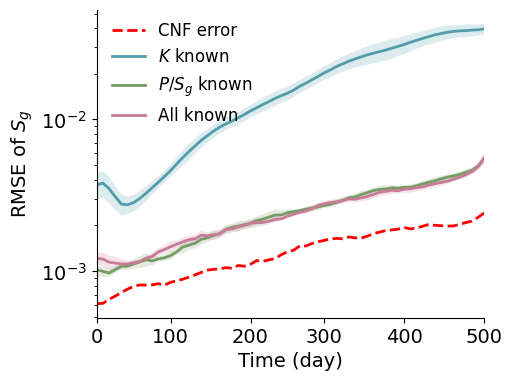

In [33]:
plt.figure(figsize=(5, 4))
x = np.arange(64)
plt.plot(x, siren_sg_rmse, label='CNF error', color='red', ls='--', lw=2)
plt.plot(x, np.mean(full_k_sg_rmse, axis=0), label=r'$K$ known', color='#529cab', lw=2)
plt.fill_between(x, 
                 np.mean(full_k_sg_rmse, axis=0) - np.std(full_k_sg_rmse, axis=0), 
                 np.mean(full_k_sg_rmse, axis=0) + np.std(full_k_sg_rmse, axis=0), 
                 color='#529cab', alpha=0.2, edgecolor='none')

plt.plot(x, np.mean(full_ps_sg_rmse, axis=0), label=r'$P$/$S_g$ known', color='#759c62', lw=2)
plt.fill_between(x, 
                 np.mean(full_ps_sg_rmse, axis=0) - np.std(full_ps_sg_rmse, axis=0), 
                 np.mean(full_ps_sg_rmse, axis=0) + np.std(full_ps_sg_rmse, axis=0), 
                 color='#759c62', alpha=0.2, edgecolor='none')

plt.plot(x, np.mean(full_all_sg_rmse, axis=0), label='All known', color='#c87a97', lw=2)
plt.fill_between(x, 
                 np.mean(full_all_sg_rmse, axis=0) - np.std(full_all_sg_rmse, axis=0), 
                 np.mean(full_all_sg_rmse, axis=0) + np.std(full_all_sg_rmse, axis=0), 
                 color='#c87a97', alpha=0.2, edgecolor='none')

# Plot error bars every 8 positions for the last three lines
# err_x = np.arange(0, 64, 8)
# plt.errorbar(err_x, np.mean(full_k_sg_rmse, axis=0)[err_x], yerr=np.std(full_k_sg_rmse, axis=0)[err_x], fmt='D', color='#529cab', capsize=3.5)
# plt.errorbar(err_x, np.mean(full_ps_sg_rmse, axis=0)[err_x], yerr=np.std(full_ps_sg_rmse, axis=0)[err_x], fmt='D', color='#759c62', capsize=3.5)
# plt.errorbar(err_x, np.mean(full_all_sg_rmse, axis=0)[err_x], yerr=np.std(full_all_sg_rmse, axis=0)[err_x], fmt='D', color='#c87a97', capsize=3.5)


labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('RMSE of $S_g$', fontsize=14)
plt.legend(fontsize=12, frameon=False, loc='upper left', bbox_to_anchor=(0, 1.01))
plt.xlim(0, 63)
plt.yscale('log')

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('error_estimation_outputs/sg_rmse.pdf', bbox_inches='tight')
plt.show()

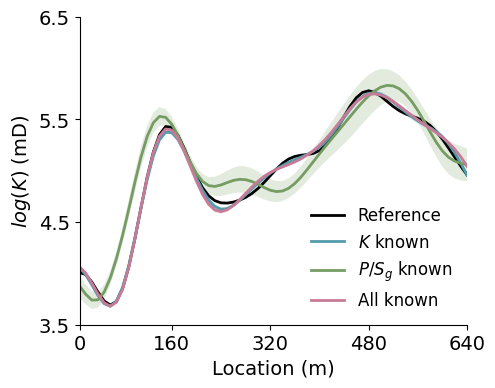

In [6]:
row_idx = 32

full_k_K = np.mean(full_k, axis=1)[..., -1]
full_ps_K = np.mean(full_ps, axis=1)[..., -1]
full_all_K = np.mean(full_all, axis=1)[..., -1]

ref_k_line = ref[0, row_idx, :, -1]
siren_k_line = siren_out[0, 0, row_idx, :, -1]
full_k_line = full_k_K[:, row_idx, :]
full_PS_line = full_ps_K[:, row_idx, :]
full_all_line = full_all_K[:, row_idx, :]

def compute_mean_std(data):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    return mean, std
def plot_line_and_fill(data, color, label):
    mean, std = compute_mean_std(data)
    plt.plot(range(64), mean, color=color, linewidth=2, ls='-', label=label)
    plt.fill_between(range(64), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')

colors = ['#529cab', '#759c62', '#c87a97']

plt.figure(figsize=(5., 4))
plt.plot(ref_k_line, color='black', label='Reference', linewidth=2, ls='-')
# plt.plot(siren_k_line, color='red', label='CNF', linewidth=2, ls='--')

plot_line_and_fill(full_k_line, colors[0], r'$K$ known')
plot_line_and_fill(full_PS_line, colors[1], r'$P$/$S_g$ known')
plot_line_and_fill(full_all_line, colors[2], 'All known')

plt.xlim(0, 63)
plt.ylim(3.5, 6.5)
plt.yticks([3.5, 4.5, 5.5, 6.5])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=14)
plt.ylabel('$log(K)$ (mD)', fontsize=14)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend(fontsize=12, frameon=False, ncols=1)
plt.savefig('error_estimation_outputs/Line_spatial_K.pdf', bbox_inches='tight')
plt.show()

Querying reference data
Querying reference data
Querying generated data
Querying generated data
Querying generated data


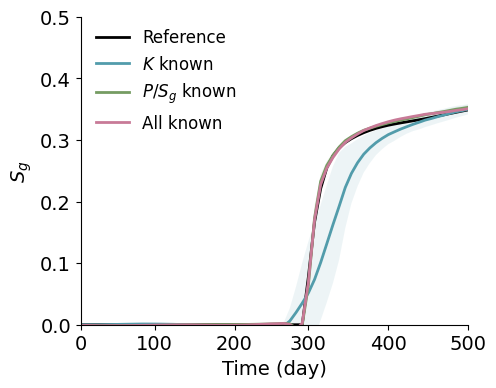

In [7]:
def query_well_data(input_data, query_pt, query_dim):
    """
    query_dim = 0: saturation
    query_dim = 1: pressure
    query_dim = 2: permeability
    """
    dims = len(input_data.shape)
    if dims == 4:
        print("Querying reference data")
        return input_data[:, query_pt[0], query_pt[1], query_dim]
    elif dims == 5:
        print("Querying generated data")
        return input_data[:, :, query_pt[0], query_pt[1], query_dim]


qt = (32, 32)
ref_sat = query_well_data(ref, qt, 1)
siren_sat = query_well_data(siren_out[0], qt, 1)

full_k_sat = query_well_data(full_k, qt, 1)
full_ps_sat = query_well_data(full_ps, qt, 1)
full_all_sat = query_well_data(full_all, qt, 1)

full_k_sat_mean = np.mean(full_k_sat, axis=0)
full_k_sat_std = np.std(full_k_sat, axis=0)
full_ps_sat_mean = np.mean(full_ps_sat, axis=0)
full_ps_sat_std = np.std(full_ps_sat, axis=0)
full_all_sat_mean = np.mean(full_all_sat, axis=0)
full_all_sat_std = np.std(full_all_sat, axis=0)

plt.figure(figsize=(5., 4))
colors = ['#529cab', '#759c62', '#c87a97']
# ---------probed point-----------
plt.plot(range(64), ref_sat, color='k', linewidth=2, label='Reference')
# plt.plot(range(64), siren_sat, color='red', linewidth=2, ls='--', label='CNF')

plt.plot(range(64), full_k_sat_mean, color=colors[0], linewidth=2, label=r'$K$ known')
plt.fill_between(range(64), full_k_sat_mean - full_k_sat_std, full_k_sat_mean + full_k_sat_std, color=colors[0], alpha=0.1, edgecolor='none', )

plt.plot(range(64), full_ps_sat_mean, color=colors[1], linewidth=2, label=r'$P$/$S_g$ known')
plt.fill_between(range(64), full_ps_sat_mean - full_ps_sat_std, full_ps_sat_mean + full_ps_sat_std, color=colors[1], alpha=0.1,edgecolor='none', )

plt.plot(range(64), full_all_sat_mean, color=colors[2], linewidth=2, label='All known')
plt.fill_between(range(64), full_all_sat_mean - full_all_sat_std, full_all_sat_mean + full_all_sat_std, color=colors[2], alpha=0.1,edgecolor='none',)


labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])

yticks = np.arange(0, 0.51, 0.1)
plt.yticks(ticks=yticks)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('$S_g$', fontsize=14)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend(fontsize=12, frameon=False, loc='upper left', bbox_to_anchor=(0, 1.01))

plt.xlim(0, 63)
plt.ylim(bottom=0)
plt.savefig('error_estimation_outputs/Line_Cart.pdf', bbox_inches='tight')
plt.show()

noise version

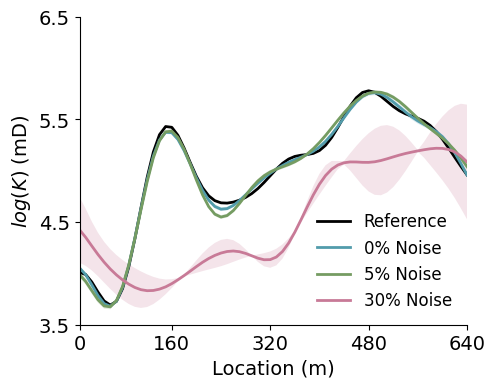

In [55]:
row_idx = 32

full_k_K = np.mean(full_k, axis=1)[..., -1]
full_k_K_noise_05 = np.mean(full_k_noise_05, axis=1)[..., -1]
full_k_K_noise_10 = np.mean(full_k_noise_10, axis=1)[..., -1]

ref_k_line = ref[0, row_idx, :, -1]
# siren_k_line = siren_out[0, 0, row_idx, :, -1]
full_k_line = full_k_K[:, row_idx, :]
full_k_noise05_line = full_k_K_noise_05[:, row_idx, :]
full_k_noise10_line = full_k_K_noise_10[:, row_idx, :]

def compute_mean_std(data):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    return mean, std
def plot_line_and_fill(data, color, label):
    mean, std = compute_mean_std(data)
    plt.plot(range(64), mean, color=color, linewidth=2, ls='-', label=label)
    plt.fill_between(range(64), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')

colors = ['#529cab', '#759c62', '#c87a97']

plt.figure(figsize=(5., 4))
plt.plot(ref_k_line, color='black', label='Reference', linewidth=2, ls='-')
# plt.plot(siren_k_line, color='red', label='CNF', linewidth=2, ls='--')

plot_line_and_fill(full_k_line, colors[0], '0% Noise')
plot_line_and_fill(full_k_noise05_line, colors[1], '5% Noise')
plot_line_and_fill(full_k_noise10_line, colors[2], '30% Noise')

plt.xlim(0, 63)
plt.ylim(3.5, 6.5)
plt.yticks([3.5, 4.5, 5.5, 6.5])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=14)
plt.ylabel('$log(K)$ (mD)', fontsize=14)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend(fontsize=12, frameon=False, ncols=1)
plt.savefig('error_estimation_outputs/Line_spatial_K_noise.pdf', bbox_inches='tight')
plt.show()

Querying reference data
Querying generated data
Querying generated data
Querying generated data


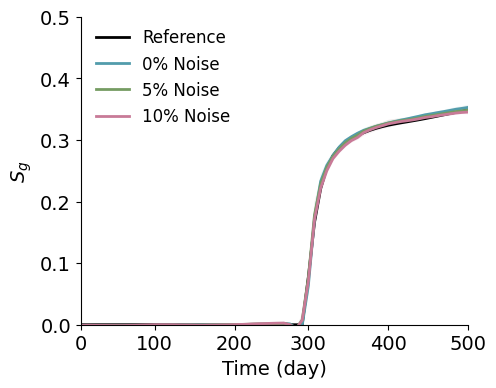

In [12]:
def query_well_data(input_data, query_pt, query_dim):
    """
    query_dim = 0: saturation
    query_dim = 1: pressure
    query_dim = 2: permeability
    """
    dims = len(input_data.shape)
    if dims == 4:
        print("Querying reference data")
        return input_data[:, query_pt[0], query_pt[1], query_dim]
    elif dims == 5:
        print("Querying generated data")
        return input_data[:, :, query_pt[0], query_pt[1], query_dim]


qt = (32, 32)
ref_sat = query_well_data(ref, qt, 1)
# siren_sat = query_well_data(siren_out[0], qt, 1)

full_ps_sat = query_well_data(full_ps, qt, 1)
full_ps_sat_noise05 = query_well_data(full_ps_noise_05, qt, 1)
full_ps_sat_noise10 = query_well_data(full_ps_noise_10, qt, 1)

full_ps_sat_mean = np.mean(full_ps_sat, axis=0)
full_ps_sat_std = np.std(full_ps_sat, axis=0)
full_ps_sat_noise05_mean = np.mean(full_ps_sat_noise05, axis=0)
full_ps_sat_noise05_std = np.std(full_ps_sat_noise05, axis=0)
full_ps_sat_noise10_mean = np.mean(full_ps_sat_noise10, axis=0)
full_ps_sat_noise10_std = np.std(full_ps_sat_noise10, axis=0)

plt.figure(figsize=(5., 4))
colors = ['#529cab', '#759c62', '#c87a97']
# ---------probed point-----------
plt.plot(range(64), ref_sat, color='k', linewidth=2, label='Reference')
# plt.plot(range(64), siren_sat, color='red', linewidth=2, ls='--', label='CNF')

plt.plot(range(64), full_ps_sat_mean, color=colors[0], linewidth=2, label='0% Noise')
plt.fill_between(range(64), full_ps_sat_mean - full_ps_sat_std, full_ps_sat_mean + full_ps_sat_std, color=colors[0], alpha=0.1, edgecolor='none', )

plt.plot(range(64), full_ps_sat_noise05_mean, color=colors[1], linewidth=2, label='5% Noise')
plt.fill_between(range(64), full_ps_sat_noise05_mean - full_ps_sat_noise05_std, full_ps_sat_noise05_mean + full_ps_sat_noise05_std, color=colors[1], alpha=0.1,edgecolor='none', )

plt.plot(range(64), full_ps_sat_noise10_mean, color=colors[2], linewidth=2, label='10% Noise')
plt.fill_between(range(64), full_ps_sat_noise10_mean - full_ps_sat_noise10_std, full_ps_sat_noise10_mean + full_ps_sat_noise10_std, color=colors[2], alpha=0.1,edgecolor='none',)


labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])

yticks = np.arange(0, 0.51, 0.1)
plt.yticks(ticks=yticks)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('$S_g$', fontsize=14)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend(fontsize=12, frameon=False, loc='upper left', bbox_to_anchor=(0, 1.01))

plt.xlim(0, 63)
plt.ylim(bottom=0)
plt.savefig('error_estimation_outputs/Line_Cart_noise.pdf', bbox_inches='tight')
plt.show()